# Guía 6 – 3.1 Regresión Lineal
**Producto de datos:** estimador de precio de viviendas.

**Objetivo:** entrenar una regresión lineal para predecir el precio de venta de una vivienda y lograr un R² ≈ 0.70 o mayor en el Test set (30 %, `random_state=10`).

> **Nota sobre el dataset.** El archivo `House_Prices.csv` es el *Ames Housing* (Kaggle *House Prices: Advanced Regression*), no el de King County citado en la guía. Los nombres de columnas cambian, por lo que se hace la equivalencia que se muestra en la tabla de abajo.

| Guía (King County) | Dataset entregado (Ames) | Comentario |
|---|---|---|
| `price` | `SalePrice` | variable objetivo |
| `sqft_living` | `GrLivArea` | área habitable sobre el suelo (sq ft) |
| `grade` | `OverallQual` | calidad de materiales y acabados (1–10) |
| `bathrooms` | `Bathrooms` = `FullBath` + 0.5·`HalfBath` | variable construida |
| `bedrooms` | `BedroomAbvGr` | dormitorios sobre el suelo |
| `view` | *(no existe)* | Ames no tiene calidad de vista; se reemplaza por las variables extra justificadas más abajo |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")
RUTA = "House_Prices.csv"   # misma carpeta que el notebook (en Colab, súbelo al entorno)

## 1. Carga y exploración

In [2]:
df = pd.read_csv(RUTA)
print(df.shape)
df[["SalePrice", "GrLivArea", "OverallQual", "FullBath", "HalfBath", "BedroomAbvGr",
    "TotalBsmtSF", "GarageCars", "YearBuilt"]].describe().T

(1460, 81)


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.195890,79442.502883,34900.0,129975.00,163000.0,214000.00,755000.0
GrLivArea,1460.0,1515.463699,525.480383,334.0,1129.50,1464.0,1776.75,5642.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
FullBath,1460.0,1.565068,0.550916,0.0,1.00,2.0,2.00,3.0
HalfBath,1460.0,0.382877,0.502885,0.0,0.00,0.0,1.00,2.0
BedroomAbvGr,1460.0,2.866438,0.815778,0.0,2.00,3.0,3.00,8.0
TotalBsmtSF,1460.0,1057.429452,438.705324,0.0,795.75,991.5,1298.25,6110.0
GarageCars,1460.0,1.767123,0.747315,0.0,1.00,2.0,2.00,4.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0


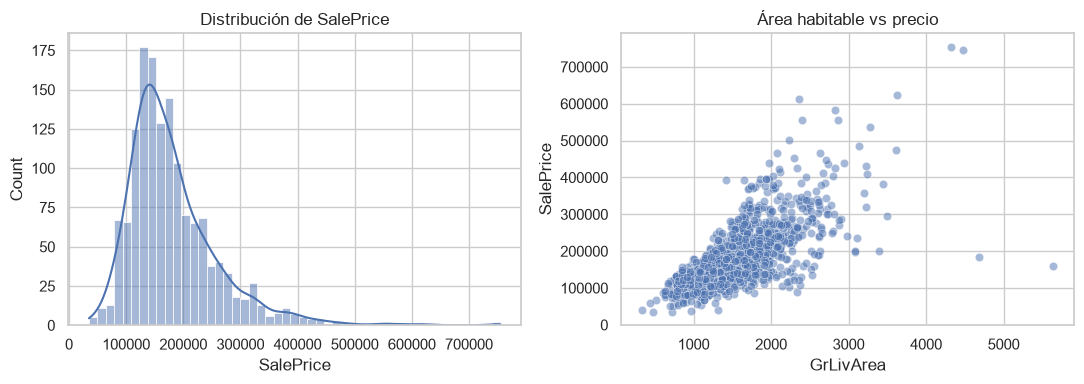

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
ax[0].set_title("Distribución de SalePrice")
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=.5, ax=ax[1])
ax[1].set_title("Área habitable vs precio")
plt.tight_layout(); plt.show()

## 2. Preprocesamiento y selección de variables
- `Bathrooms` = baños completos + 0.5 × medios baños (convención habitual).
- **Variables base (equivalentes a la guía):** `GrLivArea`, `OverallQual`, `Bathrooms`, `BedroomAbvGr`.
- **Variables añadidas (justificación):** como `view` no existe, se agregan tres predictores con fuerte relación con el precio y sin datos faltantes:
  - `TotalBsmtSF`: superficie del sótano, suma área útil que `GrLivArea` no cuenta.
  - `GarageCars`: capacidad del garaje, indicador de comodidad/estatus.
  - `YearBuilt`: antigüedad de la vivienda.
- Ninguna de estas columnas tiene valores nulos, así que no se requiere imputación.

In [4]:
df["Bathrooms"] = df["FullBath"] + 0.5 * df["HalfBath"]

features = ["GrLivArea", "OverallQual", "Bathrooms", "BedroomAbvGr",
            "TotalBsmtSF", "GarageCars", "YearBuilt"]
target = "SalePrice"

print("Nulos:", df[features + [target]].isna().sum().sum())
corr = df[features + [target]].corr()[target].drop(target).sort_values(ascending=False)
corr.to_frame("corr con SalePrice")

Nulos: 0


,corr con SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
TotalBsmtSF,0.613581
Bathrooms,0.597966
YearBuilt,0.522897
BedroomAbvGr,0.168213


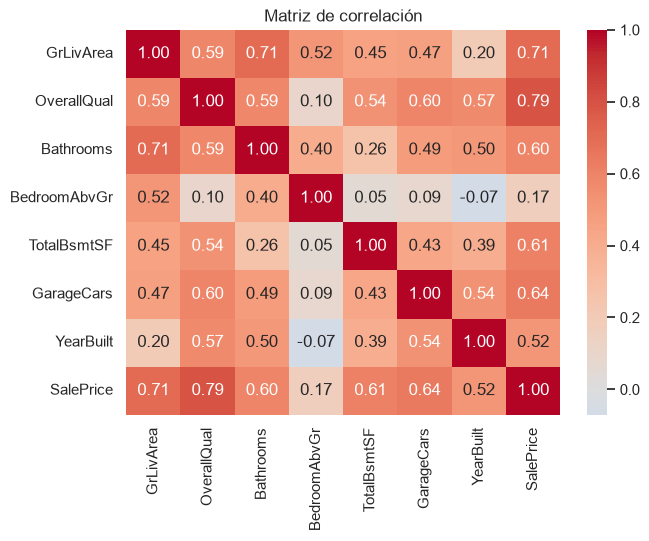

In [5]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[features + [target]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación"); plt.show()

## 3. Partición Train / Test (70 / 30, `random_state=10`)

In [6]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=10)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1022, 7) | Test: (438, 7)


## 4. Entrenamiento

In [7]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

coef = pd.DataFrame({"variable": features, "coeficiente": modelo.coef_}).sort_values("coeficiente")
print("Intercepto:", round(modelo.intercept_, 2))
coef

Intercepto: -721964.9


,variable,coeficiente
3,BedroomAbvGr,-7474.046561
2,Bathrooms,-4403.020182
4,TotalBsmtSF,19.311976
0,GrLivArea,64.359907
6,YearBuilt,335.688674
5,GarageCars,14758.590683
1,OverallQual,20632.020241


## 5. Evaluación

In [8]:
pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)

res = pd.DataFrame({
    "R²":   [r2_score(y_train, pred_train), r2_score(y_test, pred_test)],
    "MAE":  [mean_absolute_error(y_train, pred_train), mean_absolute_error(y_test, pred_test)],
    "RMSE": [np.sqrt(mean_squared_error(y_train, pred_train)), np.sqrt(mean_squared_error(y_test, pred_test))],
}, index=["Train", "Test"])
res.round(4)

,R²,MAE,RMSE
Train,0.7619,24598.5649,39327.7116
Test,0.7975,24309.6279,34440.1939


In [9]:
r2_test = r2_score(y_test, pred_test)
print(f"R² en Test = {r2_test:.4f}  ->  {'CUMPLE' if r2_test >= 0.70 else 'NO CUMPLE'} el mínimo de 0.70")

R² en Test = 0.7975  ->  CUMPLE el mínimo de 0.70


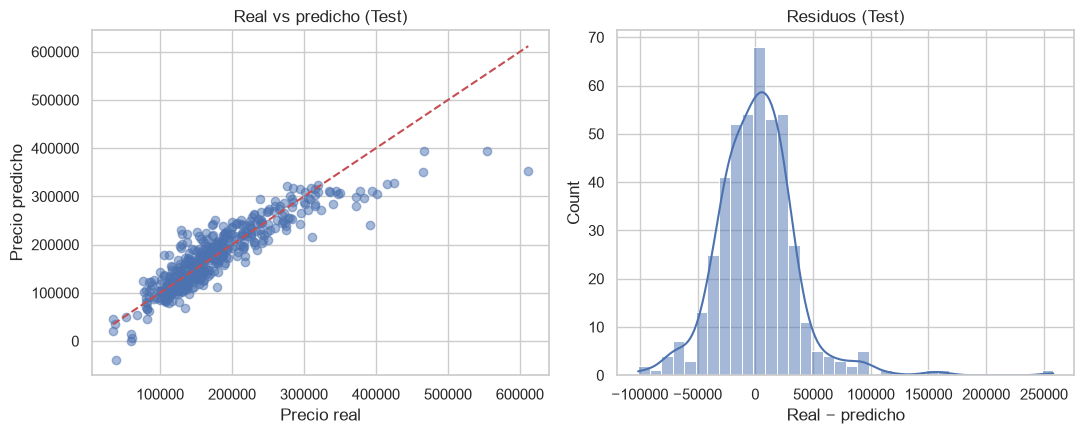

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test, pred_test, alpha=.5)
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Precio real"); ax[0].set_ylabel("Precio predicho")
ax[0].set_title("Real vs predicho (Test)")
sns.histplot(y_test - pred_test, kde=True, ax=ax[1])
ax[1].set_title("Residuos (Test)"); ax[1].set_xlabel("Real − predicho")
plt.tight_layout(); plt.show()

## 6. Interpretación
**Resultados (Test, 438 viviendas):** R² = **0.7975**, MAE ≈ \$24 310, RMSE ≈ \$34 440. **Cumple** el mínimo de 0.70 pedido por la guía.

- **R²:** el modelo explica ~80 % de la variación del precio en datos no vistos. En Train el R² es 0.762, es decir, Test no es peor que Train (diferencia atribuible al azar de la partición), por lo que no hay sobreajuste.
- **Coeficientes:** cada coeficiente es el cambio esperado en dólares por unidad, manteniendo las demás variables constantes. `OverallQual` (+\$20 600 por punto de calidad) y `GarageCars` (+\$14 800 por plaza) son los de mayor efecto unitario; `GrLivArea` suma ≈ \$64 por pie cuadrado y `YearBuilt` ≈ \$336 por año más reciente.
- **Signos negativos de `BedroomAbvGr` y `Bathrooms`:** parecen contraintuitivos, pero se explican por multicolinealidad: están muy correlacionados con `GrLivArea`. Con el área fija, más dormitorios implica cuartos más pequeños. Esos coeficientes no deben leerse de forma aislada.
- **Residuos:** los errores crecen en las casas caras y hay cola larga a la derecha, porque el precio está sesgado. Una mejora natural es modelar `log(SalePrice)`.
- **MAE / RMSE:** el error típico es de ≈ \$24 mil sobre un precio medio de ≈ \$181 mil (~13 %). El RMSE es mayor que el MAE porque penaliza más los errores grandes.

**Conclusión:** una regresión lineal simple con 7 variables supera el umbral exigido y es fácil de explicar, aunque pierde precisión en las viviendas de mayor valor.